In [1]:
import tensorflow as tf
import numpy as np
from tensorflow.keras.datasets import mnist



In [2]:
#Importing early stopping
from tensorflow.keras.callbacks import EarlyStopping
import seaborn
import matplotlib.pyplot as plt


In [3]:
# Loading dataset into train-test split 

(x_train,y_train), (x_test,y_test) = mnist.load_data()
# Normalize the dataset
x_train_scaled = x_train /255.0
x_test_scaled = x_test / 255.0

x_train_scaled.shape, y_train.shape, x_test_scaled.shape, y_test.shape


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


((60000, 28, 28), (60000,), (10000, 28, 28), (10000,))

In [4]:
# Build linear layer model.

model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(28,28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(units = 128, activation='relu'),
    tf.keras.layers.Dense(units = 58, activation='relu'),
    tf.keras.layers.Dense(units = 10, activation='softmax')                
    ])

model.compile(loss = 'sparse_categorical_crossentropy',optimizer='adam',metrics = ['accuracy'])


In [5]:
# set early stopping

early_stopping = EarlyStopping(monitor="val_loss",
    min_delta=0.001,
    patience=12,
    verbose=1,
    mode="auto",
)


Epoch 1/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9973 - loss: 0.0089 - val_accuracy: 0.9764 - val_loss: 0.1833
Epoch 2/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9983 - loss: 0.0054 - val_accuracy: 0.9724 - val_loss: 0.2075
Epoch 3/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9982 - loss: 0.0058 - val_accuracy: 0.9750 - val_loss: 0.1988
Epoch 4/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9978 - loss: 0.0066 - val_accuracy: 0.9773 - val_loss: 0.1818
Epoch 5/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9980 - loss: 0.0066 - val_accuracy: 0.9757 - val_loss: 0.2032
Epoch 6/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9981 - loss: 0.0062 - val_accuracy: 0.9752 - val_loss: 0.2197
Epoch 7/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9980 - loss: 0.0060 - val_accuracy: 0.9765 - val_loss: 0.2000
Epoch 8/20
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 2s 1ms/step - accuracy: 0.9977 - loss: 0.0075 - 

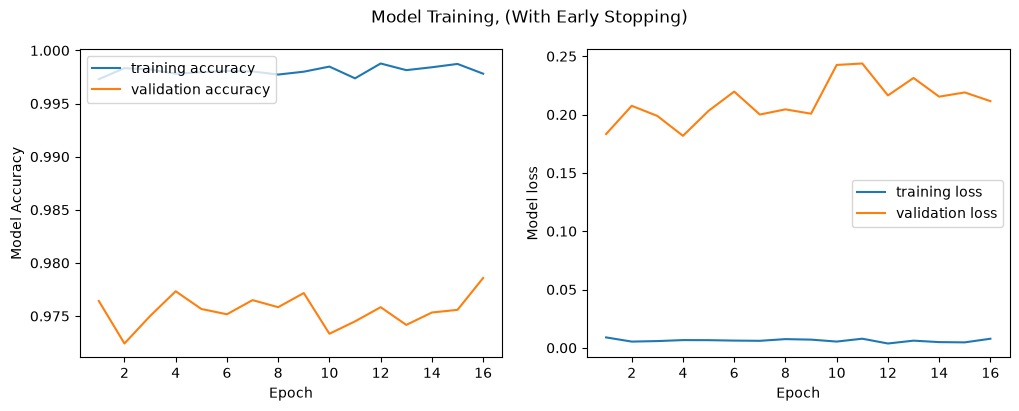

In [14]:
# Train the model

history = model.fit(x= x_train_scaled, y = y_train, validation_split=0.20,callbacks = [early_stopping],epochs=20)
fig, ax = plt.subplots(figsize = (12,4),ncols=2,nrows=1)


fig.suptitle("Model Training, (With Early Stopping)")

epochs_size = len(history.history['accuracy'])
# Fig.1 Accuracy 
ax[0].plot( [i for i in range(1,epochs_size+1)], history.history['accuracy'],label = 'training accuracy')
ax[0].plot([i for i in range(1,epochs_size+1)],  history.history['val_accuracy'],label = 'validation accuracy')
ax[0].set_xlabel("Epoch")
ax[0].set_ylabel("Model Accuracy")
ax[0].legend(loc = 'upper left')
# Fig 2 Loss

ax[1].plot(
    [i for i in range(1, epochs_size + 1)],
    history.history['loss'],
    label='training loss'
)

ax[1].plot(
    [i for i in range(1, epochs_size + 1)],
    history.history['val_loss'],
    label='validation loss'
)

ax[1].set_xlabel("Epoch")
ax[1].set_ylabel("Model loss")
ax[1].legend()

# Save the figure
fig.savefig('With Early stopping.png')

In [16]:
plt.show()
score = model.evaluate(x_test_scaled,y_test)
print(f'Model Loss on testing data is : {np.round(score[0],2)}')
print(f'Model Accuracy on testing data is : {np.round(score[1]*100,2)}')



313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 899us/step - accuracy: 0.9784 - loss: 0.1952
Model Loss on testing data is : 0.2
Model Accuracy on testing data is : 97.84
